# Ames Housing — Data Preprocessing

Complete preprocessing pipeline for two supervised tasks:
- **Regression** — predict `Year Built` (construction year)
- **Classification** — predict `House Style` (architectural typology)

**Run this notebook first.** It saves `preprocessed_data.pkl` loaded by
`regression.ipynb` and `classification.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew, kurtosis
import pickle

from sklearn.preprocessing import (PowerTransformer, StandardScaler,
                                    MinMaxScaler, OneHotEncoder, OrdinalEncoder)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from category_encoders import BinaryEncoder
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('AmesHousing.csv')
print(f'Shape: {df.shape}')
df.head(5)

Shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
df.isnull().sum()

Order               0
PID                 0
MS SubClass         0
MS Zoning           0
Lot Frontage      490
                 ... 
Mo Sold             0
Yr Sold             0
Sale Type           0
Sale Condition      0
SalePrice           0
Length: 82, dtype: int64

In [5]:
threshhold = 0.70
missing = df.isnull().mean()
print('Dropped columns (>70% missing):')
print(missing[missing > threshhold])
df.drop(columns=missing[missing > threshhold].index, inplace=True)
print(f'Shape after drop: {df.shape}')

Dropped columns (>70% missing):
Series([], dtype: float64)
Shape after drop: (2930, 78)


## Feature Engineering & Leakage Prevention

`Year Remod/Add Delta` = `Year Remod/Add` − `Year Built` captures renovation
recency without leaking a raw calendar year.  `House Style` is saved separately
as the classification target before being dropped from the feature set.

In [6]:
df.dropna(subset=['Year Built', 'House Style'], inplace=True)
df['Year Remod/Add Delta'] = df['Year Remod/Add'] - df['Year Built']
house_style_target = df['House Style'].copy()
df.drop(columns=['Order', 'PID', 'SalePrice', 'House Style',
                 'Year Remod/Add', 'Yr Sold', 'Mo Sold'], inplace=True)
print(f'Shape: {df.shape}')
df.head(3)

Shape: (2930, 72)


,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Sale Type,Sale Condition,Year Remod/Add Delta
0,20,RL,141.0,31770,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,210,62,0,0,0,0,0,WD,Normal,0
1,20,RH,80.0,11622,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,140,0,0,0,120,0,0,WD,Normal,0
2,20,RL,81.0,14267,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,393,36,0,0,0,0,12500,WD,Normal,0


## EDA: Target Variable (`Year Built`)

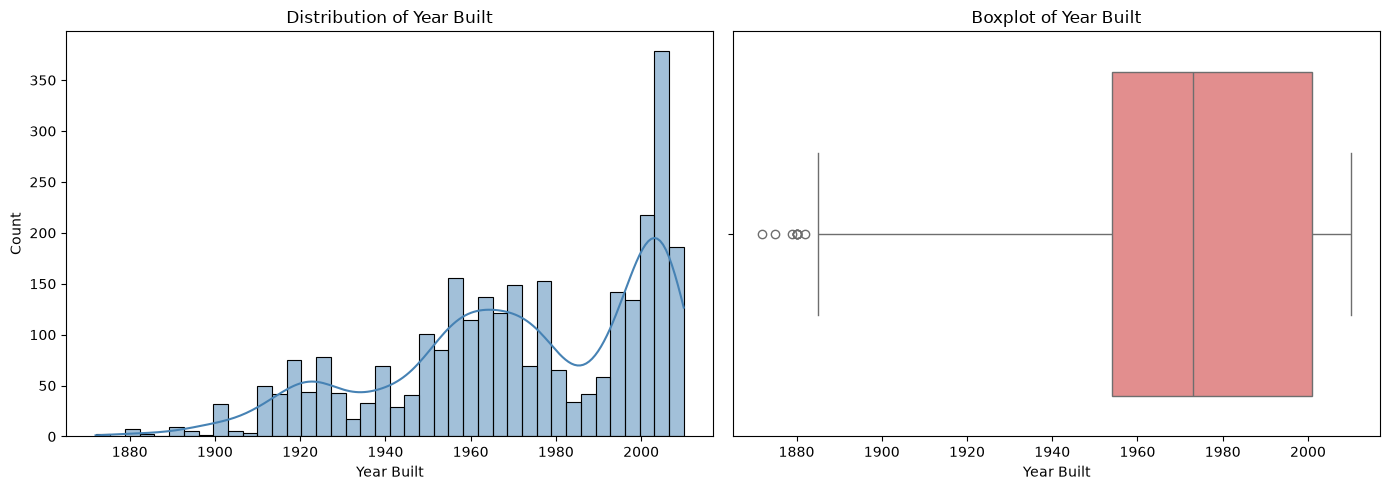

count    2930.000000
mean     1971.356314
std        30.245361
min      1872.000000
25%      1954.000000
50%      1973.000000
75%      2001.000000
max      2010.000000
Name: Year Built, dtype: float64
Skewness : -0.604
Kurtosis : -0.502


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Year Built'], bins=40, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution of Year Built')
axes[0].set_xlabel('Year Built')
sns.boxplot(x=df['Year Built'], color='lightcoral', ax=axes[1])
axes[1].set_title('Boxplot of Year Built')
plt.tight_layout()
plt.show()
print(df['Year Built'].describe())
print(f"Skewness : {df['Year Built'].skew():.3f}")
print(f"Kurtosis : {df['Year Built'].kurtosis():.3f}")

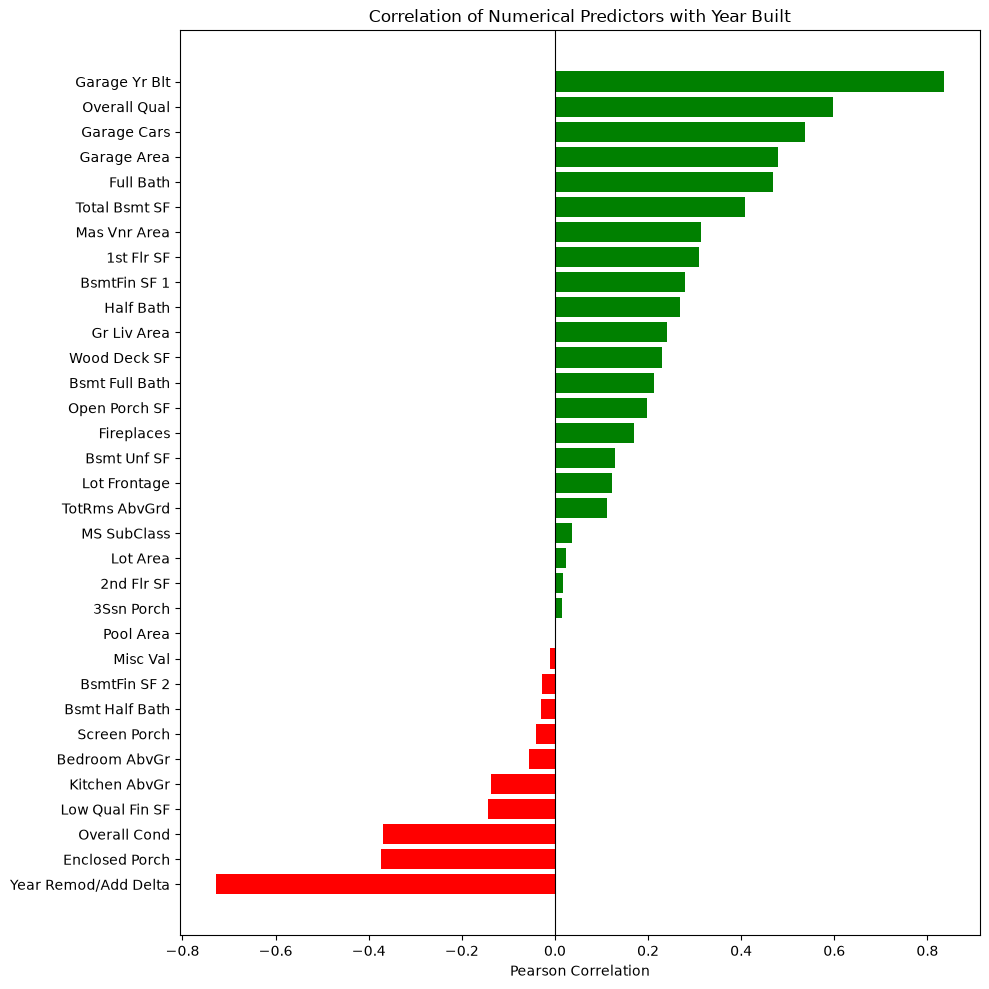

In [8]:
num_features = df.select_dtypes(include=['float64', 'int64'])
corr_with_target = (num_features.corr(numeric_only=True)['Year Built']
                    .drop('Year Built').sort_values())
colors = ['red' if x < 0 else 'green' for x in corr_with_target.values]

plt.figure(figsize=(10, 10))
plt.barh(corr_with_target.index, corr_with_target.values, color=colors)
plt.title('Correlation of Numerical Predictors with Year Built')
plt.xlabel('Pearson Correlation')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

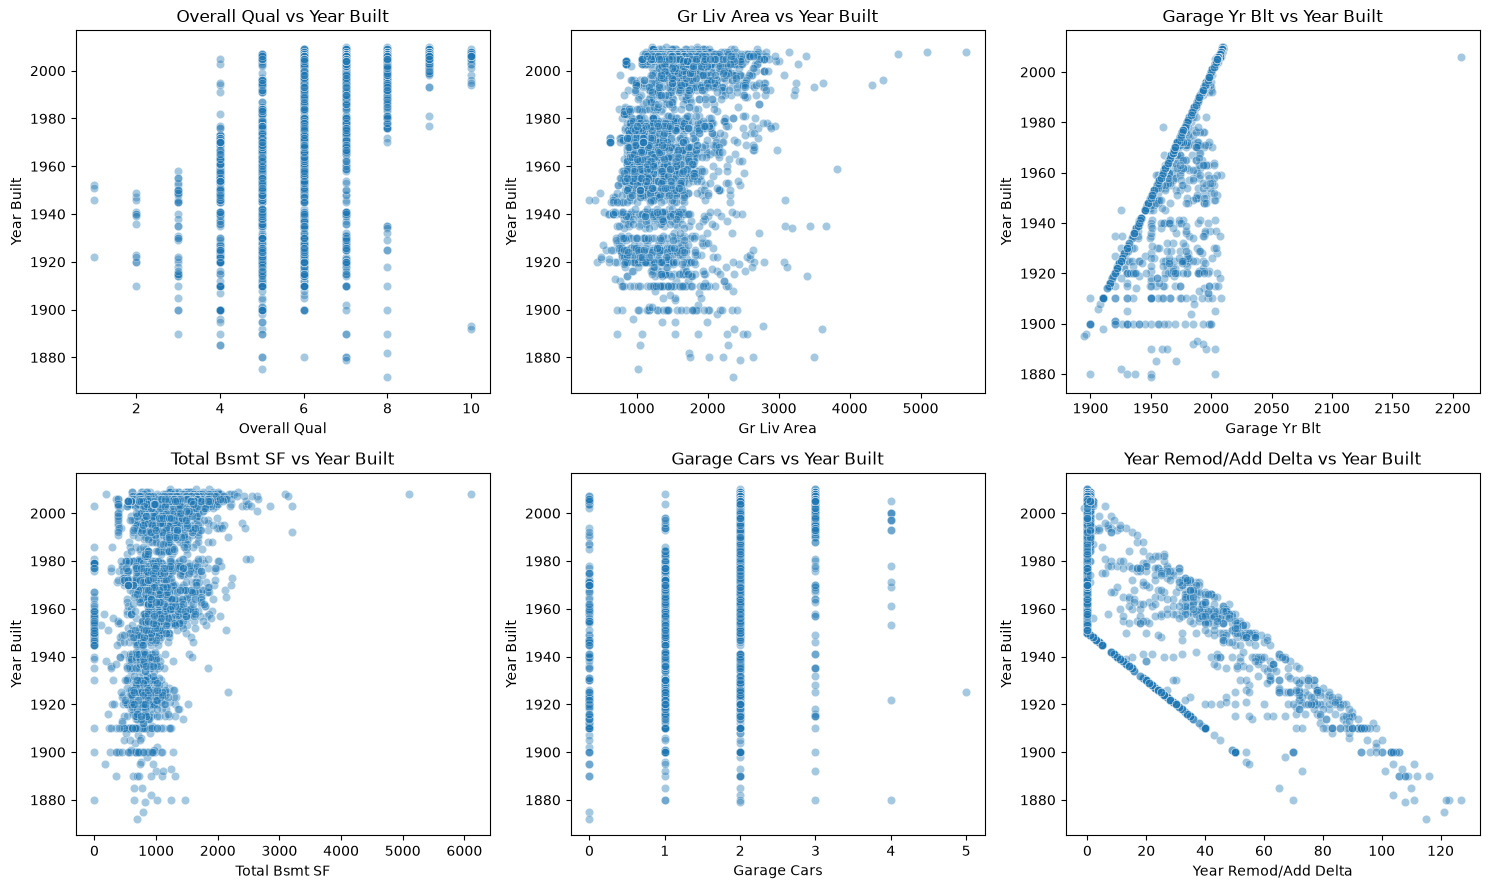

In [9]:
key_predictors = ['Overall Qual', 'Gr Liv Area', 'Garage Yr Blt',
                  'Total Bsmt SF', 'Garage Cars', 'Year Remod/Add Delta']
plt.figure(figsize=(15, 9))
for i, col in enumerate(key_predictors, 1):
    plt.subplot(2, 3, i)
    sns.scatterplot(x=df[col], y=df['Year Built'], alpha=0.4)
    plt.xlabel(col)
    plt.ylabel('Year Built')
    plt.title(f'{col} vs Year Built')
plt.tight_layout()
plt.show()

## Missing Value Analysis

In [10]:
lst_null_values = df.columns[df.isnull().any()].tolist()
print('Columns with missing values:', lst_null_values)

Columns with missing values: ['Lot Frontage', 'Mas Vnr Type', 'Mas Vnr Area', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Electrical', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual', 'Garage Cond']


In [11]:
num_clos = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
num_cols_null = [col for col in lst_null_values if col in num_clos]
print('Numerical columns with NaNs:', num_cols_null)

Numerical columns with NaNs: ['Lot Frontage', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Garage Yr Blt', 'Garage Cars', 'Garage Area']


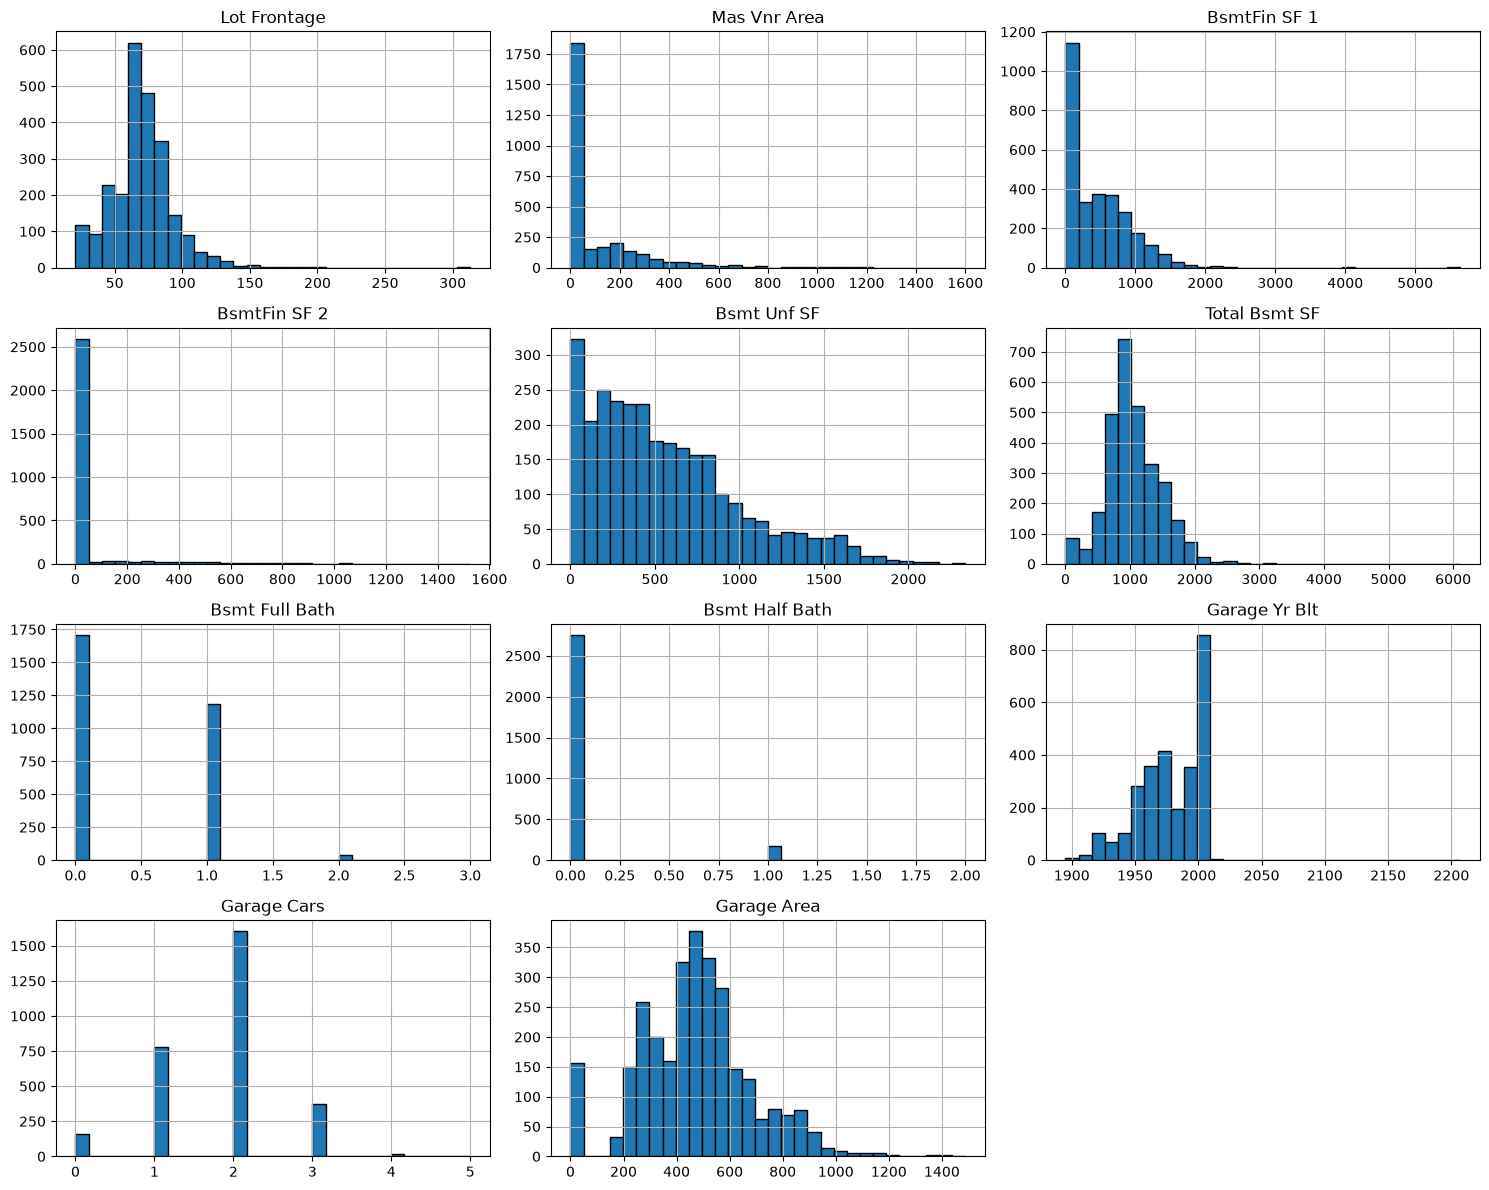

In [12]:
df[num_cols_null].hist(figsize=(15, 12), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

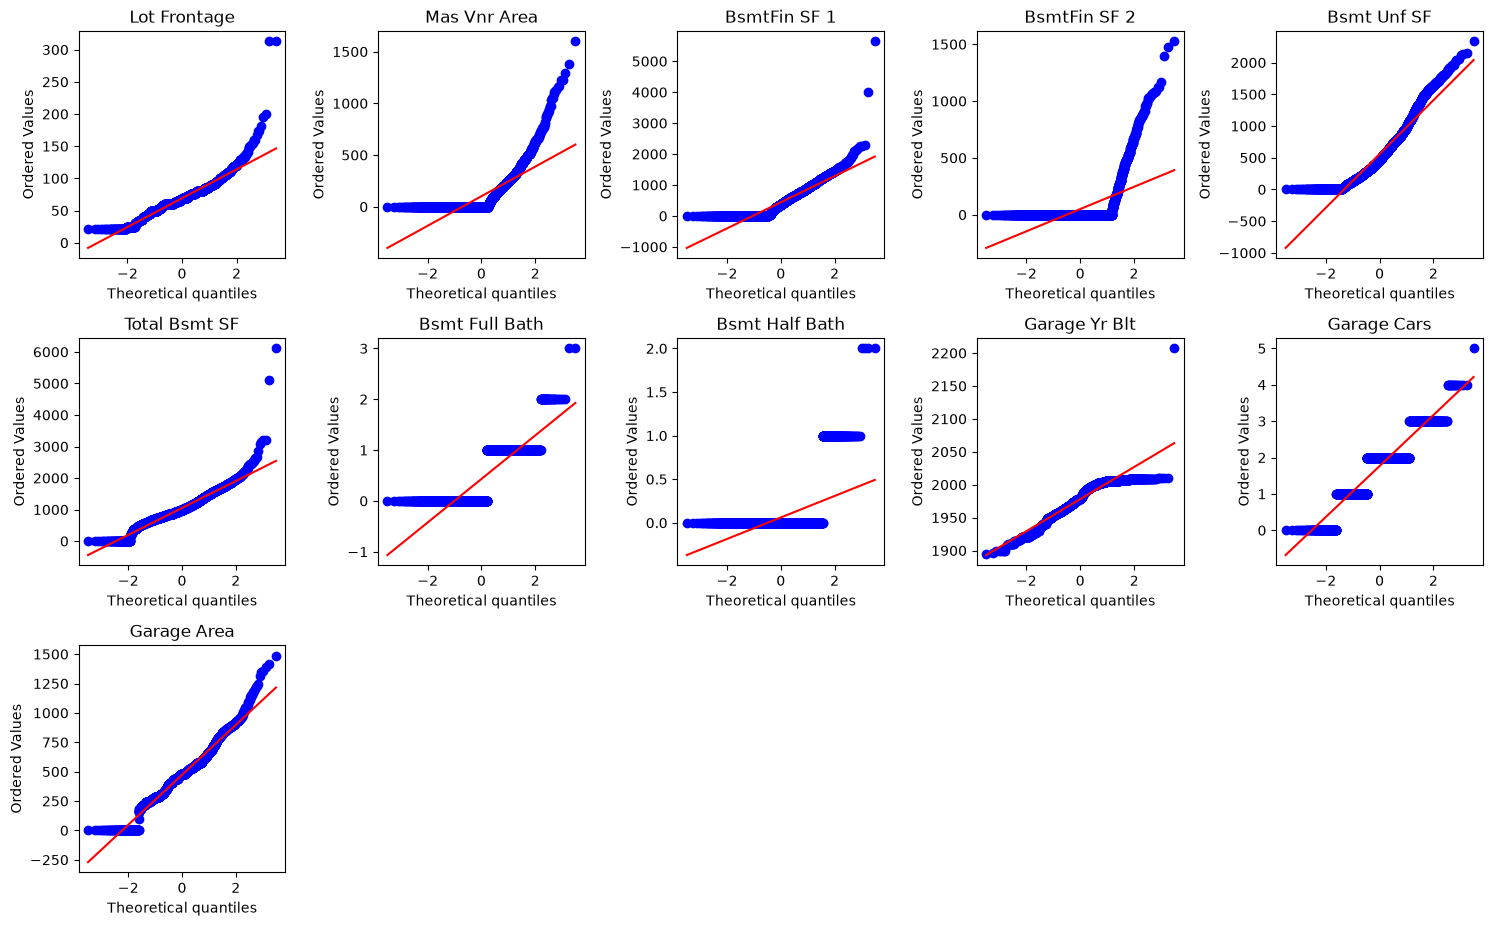

In [13]:
plt.figure(figsize=(15, 12))
for i, column in enumerate(num_cols_null, 1):
    plt.subplot(4, 5, i)
    stats.probplot(df[column].dropna(), dist='norm', plot=plt)
    plt.title(column)
plt.tight_layout()
plt.show()

In [14]:
skewness = df[num_cols_null].apply(lambda x: skew(x.dropna()))
kurt     = df[num_cols_null].apply(lambda x: kurtosis(x.dropna()))
norm_null_df = pd.DataFrame({'Skewness': skewness, 'Kurtosis': kurt})
print(norm_null_df.sort_values(by=['Skewness', 'Kurtosis']))

                Skewness   Kurtosis
Garage Yr Blt  -0.384463   1.821119
Garage Cars    -0.219724   0.242504
Garage Area     0.241870   0.947353
Bsmt Full Bath  0.616323  -0.748761
Bsmt Unf SF     0.922580   0.406779
Total Bsmt SF   1.155612   9.117977
BsmtFin SF 1    1.415457   6.845533
Lot Frontage    1.498146  11.209384
Mas Vnr Area    2.605639   9.268606
Bsmt Half Bath  3.938776  14.894223
BsmtFin SF 2    4.137858  18.747388


In [15]:
# 'str' captures pandas-3 native string dtype; 'object' covers legacy object columns
cat_cols = df.select_dtypes(include=['str', 'object', 'category']).columns.tolist()
cat_cols_null = [col for col in lst_null_values if col not in num_cols_null]
print('Categorical columns:', cat_cols)
print('Categorical with NaNs:', cat_cols_null)

Categorical columns: ['MS Zoning', 'Street', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air', 'Electrical', 'Kitchen Qual', 'Functional', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Sale Type', 'Sale Condition']
Categorical with NaNs: ['Mas Vnr Type', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Electrical', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond']


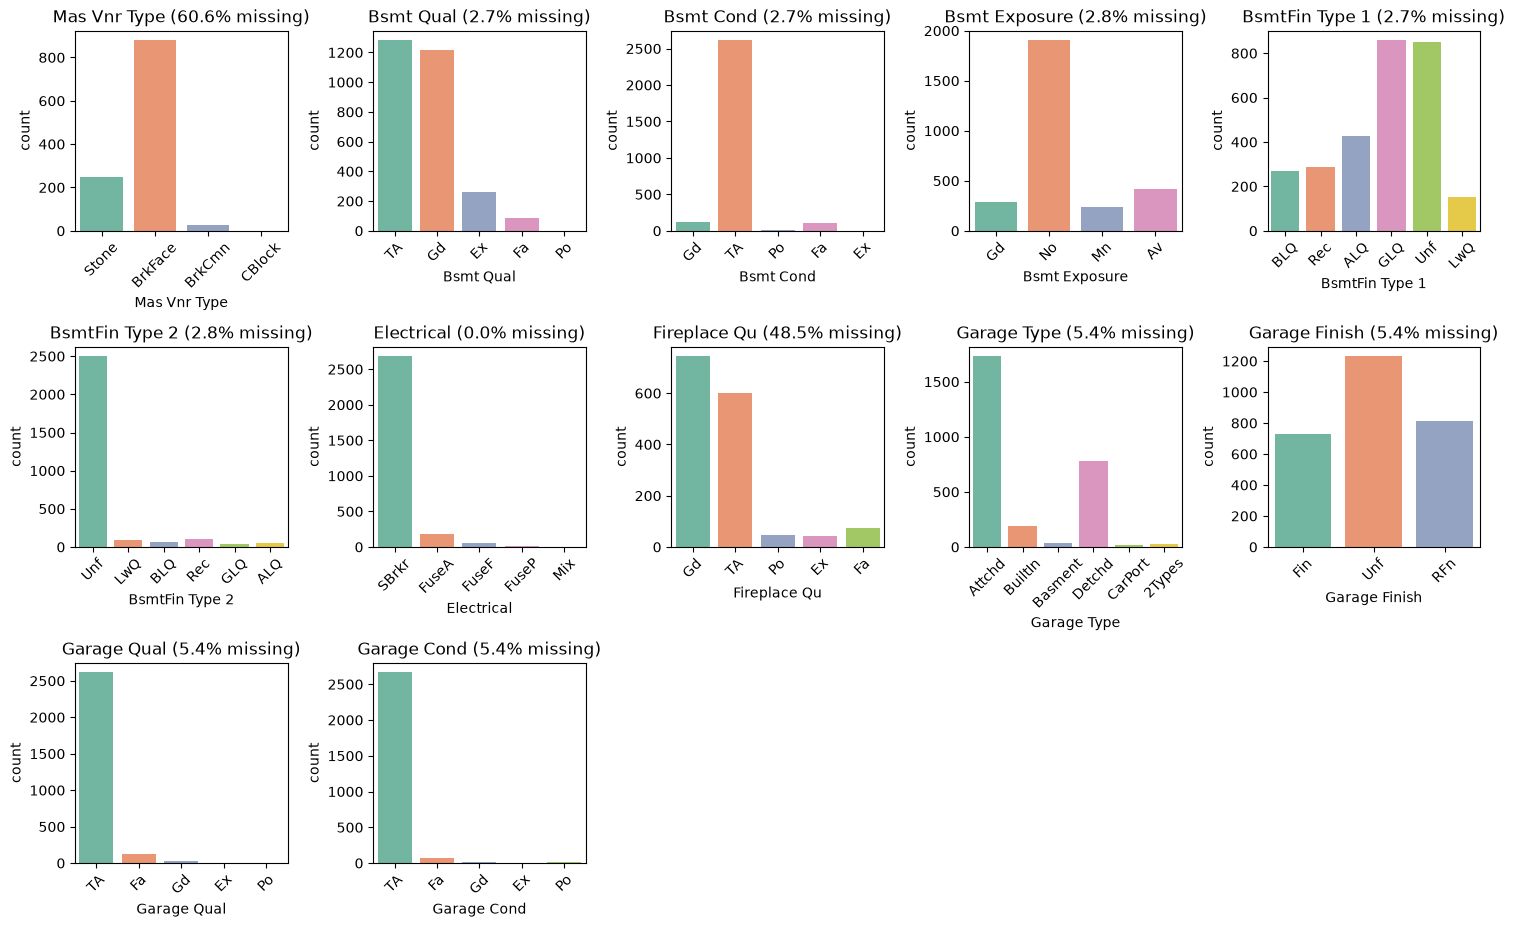

In [16]:
plt.figure(figsize=(15, 12))
for i, column in enumerate(cat_cols_null, 1):
    plt.subplot(4, 5, i)
    sns.countplot(data=df, x=column, hue=column, palette='Set2', legend=False)
    pct = df[column].isnull().mean() * 100
    plt.title(f'{column} ({pct:.1f}% missing)')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Outlier Analysis



In [17]:
def Visualize_box_hist(df, n_rows, cols):
    fig, axes = plt.subplots(n_rows, 2, figsize=(14, 4 * n_rows))
    for i, column in enumerate(cols):
        sns.histplot(df[column], bins=30, color='skyblue', ax=axes[i, 0])
        axes[i, 0].set_title(f'Histogram of {column}')
        sns.boxplot(y=df[column], ax=axes[i, 1])
        axes[i, 1].set_title(f'Box Plot of {column}')
    plt.tight_layout()
    plt.show()

Visualize_box_hist(df, len(num_clos), num_clos)

In [18]:
skew_kurt = {}
for column in num_clos:
    col_skew = df[column].skew()
    col_kurt = df[column].kurtosis()
    skew_kurt[column] = {'Skewness': col_skew, 'Kurtosis': col_kurt}
    print(f'{column:30s}  skew={col_skew:+.3f}  kurt={col_kurt:+.3f}')

MS SubClass                     skew=+1.358  kurt=+1.387
Lot Frontage                    skew=+1.499  kurt=+11.235
Lot Area                        skew=+12.821  kurt=+265.024
Overall Qual                    skew=+0.191  kurt=+0.052
Overall Cond                    skew=+0.574  kurt=+1.491
Year Built                      skew=-0.604  kurt=-0.502
Mas Vnr Area                    skew=+2.607  kurt=+9.287
BsmtFin SF 1                    skew=+1.416  kurt=+6.859
BsmtFin SF 2                    skew=+4.140  kurt=+18.781
Bsmt Unf SF                     skew=+0.923  kurt=+0.410
Total Bsmt SF                   skew=+1.156  kurt=+9.136
1st Flr SF                      skew=+1.469  kurt=+6.969
2nd Flr SF                      skew=+0.866  kurt=-0.415
Low Qual Fin SF                 skew=+12.118  kurt=+175.607
Gr Liv Area                     skew=+1.274  kurt=+4.138
Bsmt Full Bath                  skew=+0.617  kurt=-0.748
Bsmt Half Bath                  skew=+3.941  kurt=+14.922
Full Bath             

In [19]:
zero_skew_kurt = [k for k, v in skew_kurt.items()
                   if v['Skewness'] == 0 and v['Kurtosis'] == 0]
variance = df[zero_skew_kurt].var()
print('Zero-variance columns (if any):')
print(variance)

Zero-variance columns (if any):
Series([], dtype: float64)


In [20]:
# Refresh num_clos after any zero-variance drops
num_clos = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

In [21]:
# Confirm no negative values (safe to use Yeo-Johnson)
neg_cols = [col for col in num_clos if (df[col] < 0).any()]
print('Columns with negative values:', neg_cols if neg_cols else 'none')

Columns with negative values: ['Year Remod/Add Delta']


In [22]:
# Final skew / kurtosis check for scaling assignment
skew_kurt = {}
for column in num_clos:
    col_skew = df[column].skew()
    col_kurt = df[column].kurtosis()
    skew_kurt[column] = {'Skewness': col_skew, 'Kurtosis': col_kurt}
    print(f'{column:30s}  skew={col_skew:+.3f}  kurt={col_kurt:+.3f}')

MS SubClass                     skew=+1.358  kurt=+1.387
Lot Frontage                    skew=+1.499  kurt=+11.235
Lot Area                        skew=+12.821  kurt=+265.024
Overall Qual                    skew=+0.191  kurt=+0.052
Overall Cond                    skew=+0.574  kurt=+1.491
Year Built                      skew=-0.604  kurt=-0.502
Mas Vnr Area                    skew=+2.607  kurt=+9.287
BsmtFin SF 1                    skew=+1.416  kurt=+6.859
BsmtFin SF 2                    skew=+4.140  kurt=+18.781
Bsmt Unf SF                     skew=+0.923  kurt=+0.410
Total Bsmt SF                   skew=+1.156  kurt=+9.136
1st Flr SF                      skew=+1.469  kurt=+6.969
2nd Flr SF                      skew=+0.866  kurt=-0.415
Low Qual Fin SF                 skew=+12.118  kurt=+175.607
Gr Liv Area                     skew=+1.274  kurt=+4.138
Bsmt Full Bath                  skew=+0.617  kurt=-0.748
Bsmt Half Bath                  skew=+3.941  kurt=+14.922
Full Bath             

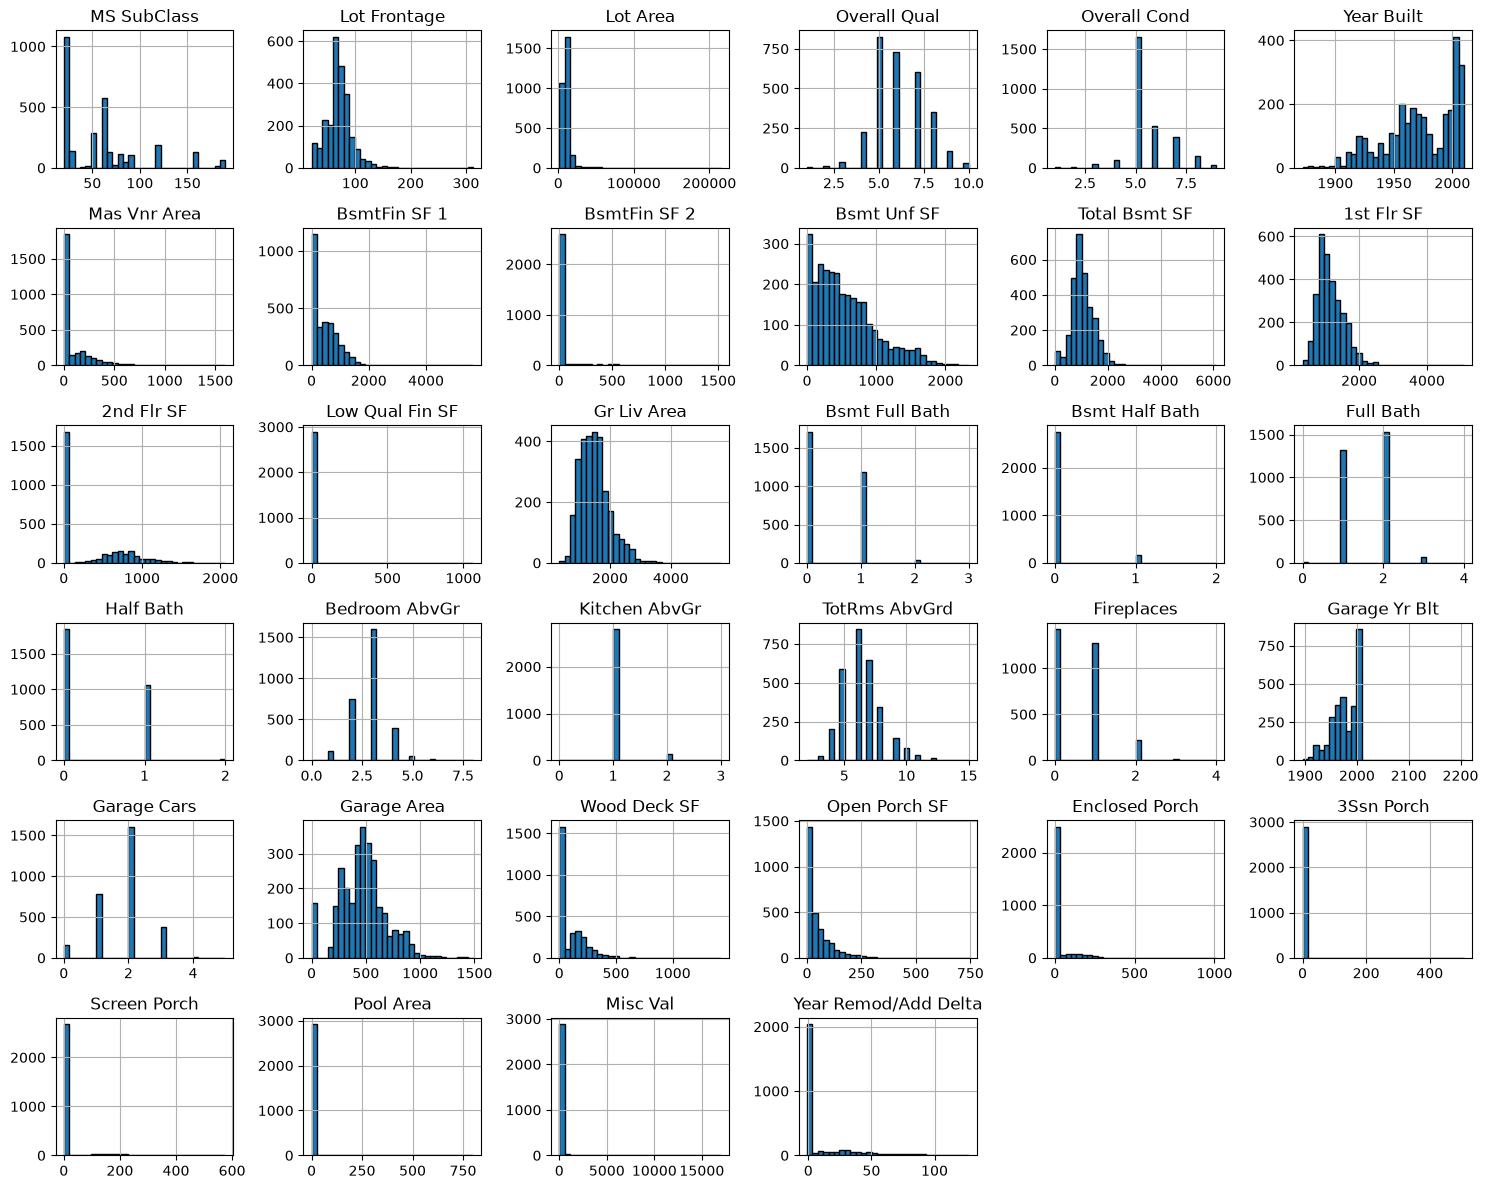

In [23]:
df_plot = df[num_clos].replace([np.inf, -np.inf], np.nan)
df_plot.hist(figsize=(15, 12), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

## Scaling & Encoding Assignments

| Group | Columns | Method |
|-------|---------|--------|
| Standardize | approx-normal features | Yeo-Johnson + StandardScaler |
| Normalize   | skewed features         | Yeo-Johnson + MinMaxScaler  |
| Ordinal     | quality / condition ratings | OrdinalEncoder |
| Nominal     | low-cardinality categorical | OneHotEncoder  |
| High-card   | >10 unique values           | BinaryEncoder  |

In [24]:
standardization = [
    'Lot Frontage', 'Lot Area', 'Overall Qual', 'Total Bsmt SF', '1st Flr SF',
    'Gr Liv Area', 'Full Bath', 'Year Remod/Add Delta', 'BsmtFin SF 1',
    'Bsmt Unf SF', 'Garage Yr Blt', 'Garage Cars', 'TotRms AbvGrd',
    'Garage Area', 'Overall Cond', 'Bedroom AbvGr',
]
normalization = [
    'MS SubClass', 'Mas Vnr Area', 'Half Bath', '2nd Flr SF',
    'Wood Deck SF', 'Open Porch SF', 'Bsmt Full Bath', 'Fireplaces',
]
print(f'Standardize : {len(standardization)} features')
print(f'Normalize   : {len(normalization)} features')

Standardize : 16 features
Normalize   : 8 features


In [25]:
ordinal_cat = [
    'Lot Shape', 'Land Slope', 'Exter Qual', 'Exter Cond', 'Bsmt Qual',
    'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2',
    'Heating QC', 'Kitchen Qual', 'Fireplace Qu', 'Garage Qual', 'Garage Cond',
    'Garage Finish', 'Functional', 'Paved Drive', 'Street', 'Central Air',
    'Electrical', 'Utilities',
]
categories = [
    ['Reg', 'IR1', 'IR2', 'IR3'],
    ['Gtl', 'Mod', 'Sev'],
    ['Ex', 'Gd', 'TA', 'Fa'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po', 'Unknown'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Gd', 'Av', 'Mn', 'No'],
    ['GLQ', 'ALQ', 'BLQ', 'Rec', 'LwQ', 'Unf', 'Unknown'],
    ['GLQ', 'ALQ', 'BLQ', 'Rec', 'LwQ', 'Unf'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po', 'Unknown'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Ex', 'Gd', 'TA', 'Fa', 'Po'],
    ['Fin', 'RFn', 'Unf', 'Unknown'],
    ['Typ', 'Min1', 'Min2', 'Mod', 'Maj1', 'Maj2', 'Sev', 'Sal'],
    ['Y', 'P', 'N'],
    ['Pave', 'Grvl'],
    ['Y', 'N'],
    ['SBrkr', 'FuseA', 'FuseF', 'FuseP', 'Mix'],
    ['AllPub', 'NoSewr', 'NoSeWa'],
]

In [26]:
def check_category_type(df, threshold=10):
    variable_info = {}
    nominal_cat   = []
    hc_cat        = []
    for col in cat_cols:
        n_unique = df[col].nunique()
        is_ord   = col in ordinal_cat
        if n_unique > threshold:
            enc = 'High cardinality'
            hc_cat.append(col)
        elif is_ord:
            enc = 'Ordinal'
        else:
            enc = 'Nominal'
            nominal_cat.append(col)
        variable_info[col] = {'Unique Categories': n_unique, 'Category Type': enc}
    return pd.DataFrame(variable_info).T, nominal_cat, hc_cat

In [27]:
variable_analysis, nominal_cat, hc_cat = check_category_type(df)
print(variable_analysis)
print(f'\nNominal         : {nominal_cat}')
print(f'High-cardinality: {hc_cat}')

               Unique Categories     Category Type
MS Zoning                      7           Nominal
Street                         2           Ordinal
Lot Shape                      4           Ordinal
Land Contour                   4           Nominal
Utilities                      3           Ordinal
Lot Config                     5           Nominal
Land Slope                     3           Ordinal
Neighborhood                  28  High cardinality
Condition 1                    9           Nominal
Condition 2                    8           Nominal
Bldg Type                      5           Nominal
Roof Style                     6           Nominal
Roof Matl                      8           Nominal
Exterior 1st                  16  High cardinality
Exterior 2nd                  17  High cardinality
Mas Vnr Type                   4           Nominal
Exter Qual                     4           Ordinal
Exter Cond                     5           Ordinal
Foundation                     

## Leakage-Safe ColumnTransformer

Every stateful step (imputer, Yeo-Johnson, scaler, encoder) is fit on the
**training fold only** inside the pipeline — no statistic leaks from the test set.

In [28]:
numeric_std = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('power',  PowerTransformer(method='yeo-johnson', standardize=True)),
])
numeric_norm = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('power',  PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scale',  MinMaxScaler()),
])
ordinal_pipe = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OrdinalEncoder(categories=categories,
                              handle_unknown='use_encoded_value',
                              unknown_value=-1)),
])
nominal_pipe = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
highcard_pipe = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', BinaryEncoder()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ('std',     numeric_std,   standardization),
        ('norm',    numeric_norm,  normalization),
        ('ordinal', ordinal_pipe,  ordinal_cat),
        ('onehot',  nominal_pipe,  nominal_cat),
        ('binary',  highcard_pipe, hc_cat),
    ],
    remainder='drop',
)
print('Preprocessor built.')

Preprocessor built.


## Build Raw Model Matrix & Train/Test Splits

Re-read the CSV and apply only structural, non-stateful steps so the pipeline
can fit all stateful transforms exclusively on the training fold.

In [29]:
df_model = pd.read_csv('AmesHousing.csv')
_missing = df_model.isnull().mean()
df_model.drop(columns=_missing[_missing > 0.70].index, inplace=True)
df_model.dropna(subset=['Year Built', 'House Style'], inplace=True)
df_model['Year Remod/Add Delta'] = df_model['Year Remod/Add'] - df_model['Year Built']
house_style_target = df_model['House Style'].copy()
df_model.drop(columns=['Order', 'PID', 'SalePrice', 'House Style',
                       'Year Remod/Add', 'Yr Sold', 'Mo Sold'], inplace=True)

y = df_model['Year Built']
X = df_model.drop(columns='Year Built')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Feature matrix : {X.shape}')
print(f'Train {X_train.shape}  |  Test {X_test.shape}')

Feature matrix : (2930, 71)
Train (2344, 71)  |  Test (586, 71)


## Classification Task Setup

Geometry-only features (temporal columns blocked) for predicting typology.

In [30]:
X_reg = X
y_reg = y
preprocessor_reg = preprocessor

y_clf = house_style_target.copy()
typology_map = {
    '1Story': 'Single-story',
    '2Story': 'Multi-story', '2.5Fin': 'Multi-story', '2.5Unf': 'Multi-story',
    '1.5Fin': '1.5-story',   '1.5Unf': '1.5-story',
    'SLvl':   'Split-level', 'SFoyer': 'Split-level',
}
y_clf = y_clf.map(typology_map).fillna(y_clf)

clf_blocklist = {'Year Built', 'Garage Yr Blt', 'Year Remod/Add Delta', 'MS SubClass'}
clf_features  = [c for c in X.select_dtypes(include=['number']).columns
                 if c not in clf_blocklist]
X_clf = X[clf_features]

preprocessor_clf = ColumnTransformer(
    transformers=[('geom', Pipeline(steps=[
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
    ]), clf_features)],
    remainder='drop',
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print('Class distribution:')
print(y_clf.value_counts())
print(f'\nRegression     : train {X_train_reg.shape}  test {X_test_reg.shape}')
print(f'Classification : train {X_train_clf.shape}  test {X_test_clf.shape}')
print(f'Geometry features ({len(clf_features)}): {clf_features}')

Class distribution:
House Style
Single-story    1481
Multi-story      905
1.5-story        333
Split-level      211
Name: count, dtype: int64

Regression     : train (2344, 71)  test (586, 71)
Classification : train (2344, 30)  test (586, 30)
Geometry features (30): ['Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val']


## Save Artifacts to `preprocessed_data.pkl`

In [31]:
artifacts = {
    # Shared raw matrix
    'X': X, 'y': y,
    # Regression
    'X_reg': X_reg, 'y_reg': y_reg,
    'X_train': X_train, 'X_test': X_test,
    'y_train': y_train, 'y_test': y_test,
    'X_train_reg': X_train_reg, 'X_test_reg': X_test_reg,
    'y_train_reg': y_train_reg, 'y_test_reg': y_test_reg,
    'preprocessor': preprocessor,
    'preprocessor_reg': preprocessor_reg,
    # Classification
    'X_clf': X_clf, 'y_clf': y_clf,
    'X_train_clf': X_train_clf, 'X_test_clf': X_test_clf,
    'y_train_clf': y_train_clf, 'y_test_clf': y_test_clf,
    'preprocessor_clf': preprocessor_clf,
    'clf_features': clf_features,
}
with open('preprocessed_data.pkl', 'wb') as f:
    pickle.dump(artifacts, f)
print('Saved: preprocessed_data.pkl')
print('Keys:', list(artifacts.keys()))

Saved: preprocessed_data.pkl
Keys: ['X', 'y', 'X_reg', 'y_reg', 'X_train', 'X_test', 'y_train', 'y_test', 'X_train_reg', 'X_test_reg', 'y_train_reg', 'y_test_reg', 'preprocessor', 'preprocessor_reg', 'X_clf', 'y_clf', 'X_train_clf', 'X_test_clf', 'y_train_clf', 'y_test_clf', 'preprocessor_clf', 'clf_features']
